# Human-context chess outcome prediction

**CA6001 — AI Algorithms Fundamentals & Application**  
**Data:** [Chess Game Dataset (Lichess), Kaggle](https://www.kaggle.com/datasets/datasnaek/chess)

## Research question

Stockfish can evaluate the objective strength of a chess position, but games between human players are also shaped by rating, time control, and how difficult an advantage is to convert. **Can pre-match human context and a few transparent position features improve the prediction of human game outcomes beyond Stockfish's WDL estimate alone?**

The notebook follows one compact, interpretable experimental line:

1. Download, inspect, clean, and split games at game level.
2. Establish how much can be predicted before play from ratings, rated status, and time control.
3. Extract four Stockfish indicators (`score_cp`, `score_mate`, `wdl_wins`, and `wdl_draws`) and three transparent features (`ply`, `material_total`, and `material_diff`).
4. Compare three in-game predictors: direct Stockfish WDL, a learned position-only model, and the main human-context joint model.
5. Track all three predictors as moves become available, using percentage progress only for retrospective test reporting.

> **Leakage boundary.** Final game length and percentage progress are never model inputs. Training and validation positions are sampled at fixed ply counts. Percentages are used only to locate reporting positions in the untouched test set. Every position feature is calculated from the current board, and all scores are oriented from White's perspective.

In [1]:
from __future__ import annotations

import hashlib
import io
import os
import random
import urllib.request
import warnings
import zipfile
import tarfile
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import chess
import chess.engine
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    log_loss,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 6001
random.seed(SEED)
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print({
    "python_seed": SEED,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "python_chess": chess.__version__,
})

{'python_seed': 6001, 'pandas': '3.1.0', 'scikit_learn': '1.9.1', 'python_chess': '1.11.2'}


## 1. Acquire the source data

The public Kaggle API endpoint does not require credentials for this dataset. The cell is idempotent: it downloads only when `data/games.csv` is absent, verifies that the archive contains the expected member, writes to a temporary file, and atomically replaces the destination. The printed SHA-256 digest makes the exact input auditable.

In [2]:
DATA_URL = "https://www.kaggle.com/api/v1/datasets/download/datasnaek/chess"
STOCKFISH_URL = "https://github.com/official-stockfish/Stockfish/releases/download/sf_19/stockfish-linux-x86-64-universal.tar.gz"
STOCKFISH_ARCHIVE_SHA256 = "0f83d24cc46d2c66c60f16001af5444873bc112b7d028594513426894c12da19"
DATA_DIR = Path("data")
CSV_PATH = DATA_DIR / "games.csv"
DEFAULT_STOCKFISH_PATH = Path("vendor/stockfish/stockfish-linux-x86-64-universal")


def acquire_data(url: str = DATA_URL, destination: Path = CSV_PATH) -> Path:
    """Download and atomically materialize the public Kaggle CSV when needed."""
    if destination.exists():
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(url, timeout=120) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        if "games.csv" not in archive.namelist():
            raise RuntimeError("The downloaded archive does not contain games.csv.")
        payload = archive.read("games.csv")
    temporary = destination.with_suffix(".csv.tmp")
    temporary.write_bytes(payload)
    temporary.replace(destination)
    return destination


def acquire_stockfish(destination: Path = DEFAULT_STOCKFISH_PATH) -> Path:
    """Acquire the pinned Stockfish 19 Linux binary or use STOCKFISH_EXECUTABLE."""
    configured = os.environ.get("STOCKFISH_EXECUTABLE")
    if configured:
        executable = Path(configured).expanduser()
        if not executable.exists():
            raise FileNotFoundError("STOCKFISH_EXECUTABLE does not exist.")
        return executable
    if destination.exists():
        return destination
    if os.name != "posix":
        raise RuntimeError("Set STOCKFISH_EXECUTABLE to a compatible Stockfish binary on this platform.")
    with urllib.request.urlopen(STOCKFISH_URL, timeout=180) as response:
        archive_bytes = response.read()
    digest = hashlib.sha256(archive_bytes).hexdigest()
    if digest != STOCKFISH_ARCHIVE_SHA256:
        raise RuntimeError("The Stockfish archive hash does not match the pinned release.")
    member_name = "stockfish/stockfish-linux-x86-64-universal"
    with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
        member = archive.getmember(member_name)
        source = archive.extractfile(member)
        if source is None:
            raise RuntimeError("The Stockfish executable is missing from the archive.")
        payload = source.read()
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(".tmp")
    temporary.write_bytes(payload)
    temporary.chmod(0o755)
    temporary.replace(destination)
    return destination


source_path = acquire_data()
stockfish_path = acquire_stockfish()
source_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
stockfish_hash = hashlib.sha256(stockfish_path.read_bytes()).hexdigest()
print(f"Dataset: {source_path.resolve()} ({source_path.stat().st_size / 1_000_000:.2f} MB)")
print(f"Dataset SHA-256: {source_hash}")
print(f"Stockfish: {stockfish_path.resolve()}")
print(f"Stockfish SHA-256: {stockfish_hash}")

Dataset: /home/gushucheng/Chess/data/games.csv (7.67 MB)
Dataset SHA-256: e7aadff104a610afb5403caf81c1461babecb0dc87760ff5eea7dc0e7a4a8129
Stockfish: /home/gushucheng/Chess/vendor/stockfish/stockfish-linux-x86-64-universal
Stockfish SHA-256: 0f83d24cc46d2c66c60f16001af5444873bc112b7d028594513426894c12da19


## 2. Initial inspection, cleaning, and data split

The target is genuinely multiclass. Macro-F1 is the primary selection metric because a high overall accuracy can conceal failure on the comparatively rare draw class; accuracy and multiclass log loss are reported alongside it. Duplicates are removed before splitting, and the split is stratified by outcome. A fixed random seed makes it reproducible.

In [3]:
raw = pd.read_csv(source_path)
print(f"Raw shape: {raw.shape}")
display(raw.head(3))

inspection = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100).round(2),
    "unique": raw.nunique(dropna=False),
})
display(inspection)
print(f"Duplicate game IDs: {raw['id'].duplicated().sum()}")
print("Outcome counts:")
display(raw["winner"].value_counts(dropna=False).to_frame("count"))

Raw shape: (20058, 16)


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3


,dtype,missing,missing_pct,unique
id,str,0,0.0,19113
rated,bool,0,0.0,2
created_at,float64,0,0.0,13151
last_move_at,float64,0,0.0,13186
turns,int64,0,0.0,211
victory_status,str,0,0.0,4
winner,str,0,0.0,3
increment_code,str,0,0.0,400
white_id,str,0,0.0,9438
white_rating,int64,0,0.0,1516


Duplicate game IDs: 945
Outcome counts:


,count
winner,
white,10001
black,9107
draw,950


In [4]:
VALID_WINNERS = {"black", "draw", "white"}
LABEL_TO_INT = {"black": 0, "draw": 1, "white": 2}
CLASS_NAMES = np.array(["black", "draw", "white"])


def clean_games(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Apply explicit quality rules and return clean rows plus an audit trail."""
    audit = {}
    work = frame.copy()
    audit["raw_rows"] = len(work)
    work = work.drop_duplicates(subset="id", keep="first")
    audit["duplicate_ids_removed"] = audit["raw_rows"] - len(work)

    valid_target = work["winner"].isin(VALID_WINNERS)
    valid_ratings = work["white_rating"].between(100, 4000) & work["black_rating"].between(100, 4000)
    valid_moves = work["moves"].fillna("").str.strip().ne("")
    parsed_time = work["increment_code"].astype(str).str.extract(r"^(\d+)\+(\d+)$").astype(float)
    valid_time = parsed_time.notna().all(axis=1)
    keep = valid_target & valid_ratings & valid_moves & valid_time
    audit["invalid_target_removed"] = int((~valid_target).sum())
    audit["invalid_rating_removed"] = int((~valid_ratings).sum())
    audit["empty_move_list_removed"] = int((~valid_moves).sum())
    audit["invalid_time_control_removed"] = int((~valid_time).sum())

    work = work.loc[keep].copy().reset_index(drop=True)
    parsed_time = parsed_time.loc[keep].reset_index(drop=True)
    work["base_minutes"] = parsed_time[0].astype(int)
    work["increment_seconds"] = parsed_time[1].astype(int)
    work["rated_int"] = work["rated"].astype(int)
    work["move_count"] = work["moves"].str.split().str.len()
    work["rating_diff"] = work["white_rating"] - work["black_rating"]
    work["rating_mean"] = (work["white_rating"] + work["black_rating"]) / 2
    work["rating_gap"] = work["rating_diff"].abs()
    work["log_base_minutes"] = np.log1p(work["base_minutes"])
    work["white_elo_expectation"] = 1 / (1 + 10 ** (-work["rating_diff"] / 400))
    work["target"] = work["winner"].map(LABEL_TO_INT).astype(int)
    audit["clean_rows"] = len(work)
    return work, pd.Series(audit, name="count")


games, cleaning_audit = clean_games(raw)
display(cleaning_audit.to_frame())
print(f"Clean shape: {games.shape}")
print("Declared turns minus tokenized SAN count:")
display((games["turns"] - games["move_count"]).value_counts().head().to_frame("games"))

,count
raw_rows,20058
duplicate_ids_removed,945
invalid_target_removed,0
invalid_rating_removed,0
empty_move_list_removed,0
invalid_time_control_removed,0
clean_rows,19113


Clean shape: (19113, 26)
Declared turns minus tokenized SAN count:


,games
0,19113


In [5]:
all_indices = np.arange(len(games))
train_idx, holdout_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=games["target"],
)
val_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=games.loc[holdout_idx, "target"],
)

split_by_index = np.full(len(games), "", dtype=object)
split_by_index[train_idx] = "train"
split_by_index[val_idx] = "validation"
split_by_index[test_idx] = "test"
games["split"] = split_by_index

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert games["id"].is_unique

split_summary = (
    games.groupby(["split", "winner"], observed=True)
    .size()
    .unstack(fill_value=0)
    .assign(total=lambda x: x.sum(axis=1))
)
display(split_summary)

winner,black,draw,white,total
split,,,,
test,1302,133,1432,2867
train,6076,622,6681,13379
validation,1302,133,1432,2867


## 3. Pre-match statistics, correlation analysis, and visualisation

`opening_eco`, `opening_name`, and `opening_ply` are derived from moves and are therefore excluded from pre-match modelling. Player IDs are also excluded: memorising frequent players would weaken generalisation to unseen players. Game duration, final turn count, and termination status become known only after or during play and are outcome-leaking for the pre-match task.

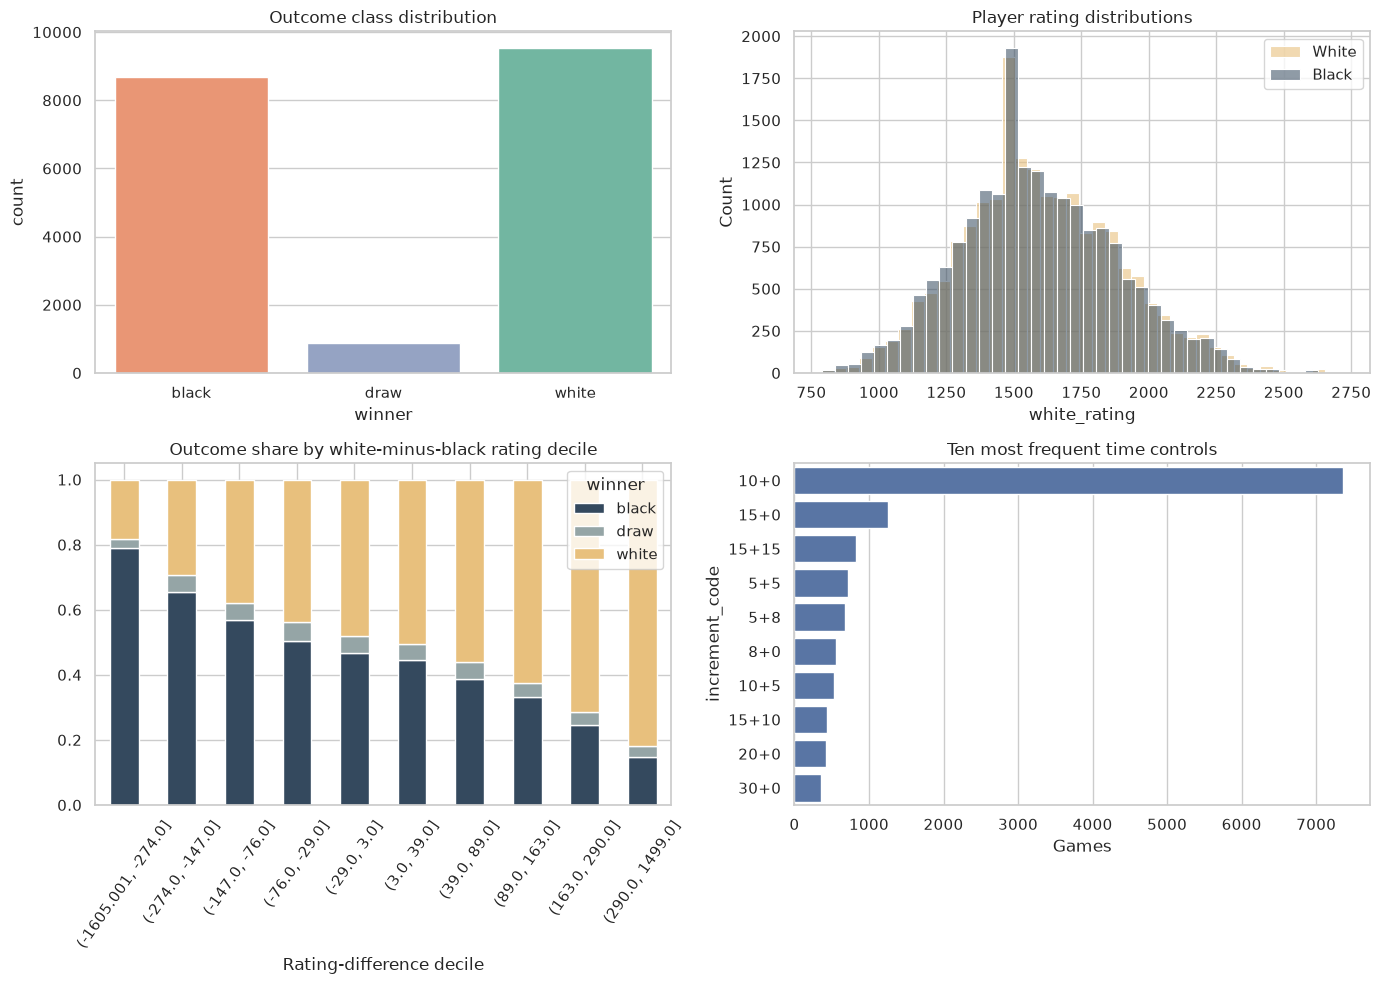

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=games, x="winner", order=CLASS_NAMES, ax=axes[0, 0], palette="Set2", hue="winner", legend=False)
axes[0, 0].set_title("Outcome class distribution")

sns.histplot(games["white_rating"], bins=40, color="#e8c07d", alpha=0.6, label="White", ax=axes[0, 1])
sns.histplot(games["black_rating"], bins=40, color="#34495e", alpha=0.55, label="Black", ax=axes[0, 1])
axes[0, 1].legend()
axes[0, 1].set_title("Player rating distributions")

rating_bins = pd.qcut(games["rating_diff"], q=10, duplicates="drop")
win_by_rating = pd.crosstab(rating_bins, games["winner"], normalize="index")
win_by_rating.plot(kind="bar", stacked=True, color=["#34495e", "#95a5a6", "#e8c07d"], ax=axes[1, 0])
axes[1, 0].set_title("Outcome share by white-minus-black rating decile")
axes[1, 0].set_xlabel("Rating-difference decile")
axes[1, 0].tick_params(axis="x", labelrotation=55)

top_controls = games["increment_code"].value_counts().head(10).index
sns.countplot(
    data=games[games["increment_code"].isin(top_controls)],
    y="increment_code",
    order=top_controls,
    ax=axes[1, 1],
    color="#4c72b0",
)
axes[1, 1].set_title("Ten most frequent time controls")
axes[1, 1].set_xlabel("Games")

plt.tight_layout()
fig.savefig(FIGURE_DIR / "01_eda_overview.png", dpi=300, bbox_inches="tight")
plt.show()

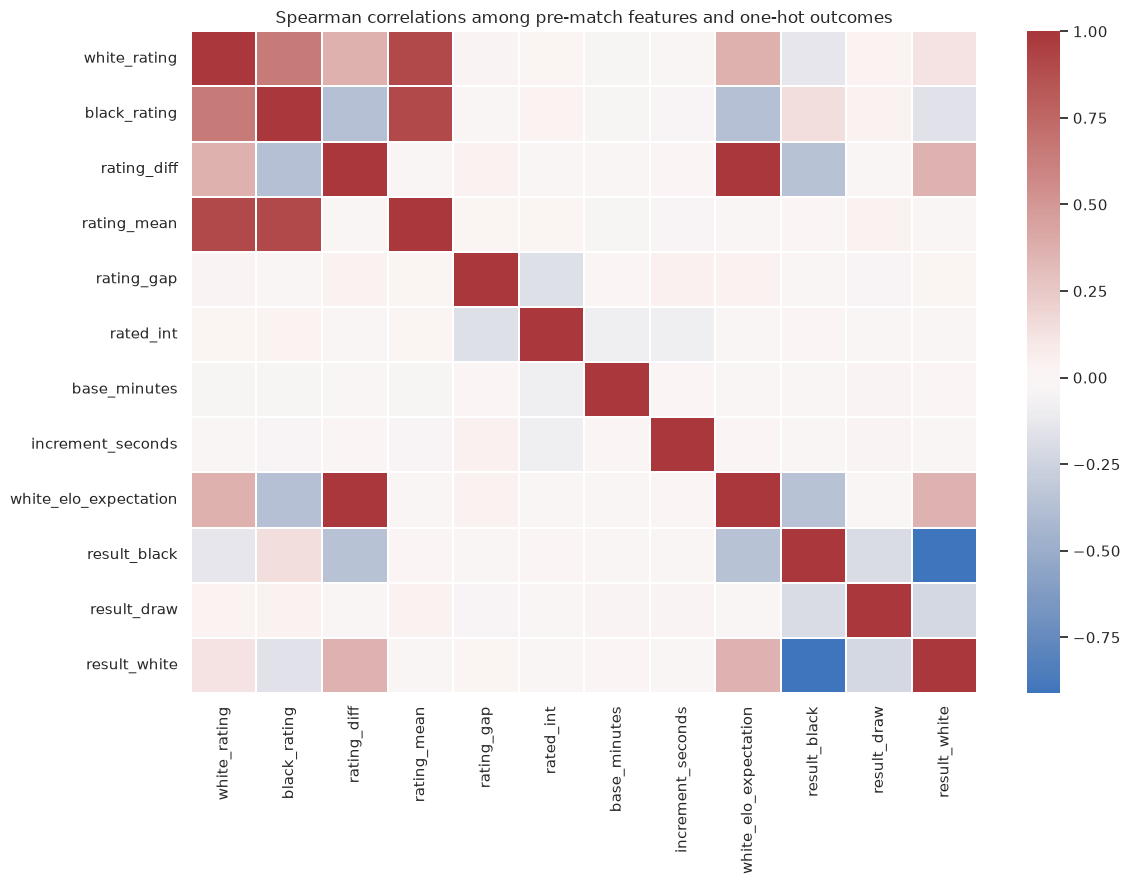

white_rating                 black_rating                 rating_diff  \
               mean  median     std         mean  median     std        mean   
winner                                                                         
black       1550.82  1527.0  282.50      1639.27  1610.0  289.45      -88.45   
draw        1649.32  1623.5  308.86      1642.19  1627.0  301.63        7.13   
white       1634.73  1603.0  288.76      1540.43  1517.0  281.71       94.30   

                      rating_gap                base_minutes                
       median     std       mean median     std         mean median    std  
winner                                                                      
black   -52.0  229.32     171.52  114.5  176.03        13.52   10.0  16.41  
draw     -2.5  210.33     144.33   93.5  153.08        16.59   10.0  24.38  
white    59.0  234.03     175.68  117.0  181.09        13.77   10.0  16.81

In [7]:
correlation_frame = games[[
    "white_rating", "black_rating", "rating_diff", "rating_mean", "rating_gap",
    "rated_int", "base_minutes", "increment_seconds", "white_elo_expectation",
]].copy()
outcome_dummies = pd.get_dummies(games["winner"], prefix="result", dtype=float)
corr = pd.concat([correlation_frame, outcome_dummies], axis=1).corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="vlag", center=0, square=False, linewidths=0.3)
plt.title("Spearman correlations among pre-match features and one-hot outcomes")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_prematch_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

display(
    games.groupby("winner")[["white_rating", "black_rating", "rating_diff", "rating_gap", "base_minutes"]]
    .agg(["mean", "median", "std"])
    .round(2)
)

## 4. Pre-match models

Three levels are compared:

- majority-class dummy: a necessary sanity baseline;
- class-balanced multinomial logistic regression: a transparent linear AI model;
- histogram gradient boosting: a nonlinear tree ensemble in the same broad boosting family as XGBoost, chosen here because it is fast, supports missing-value-safe tabular learning, and is already maintained in scikit-learn.

Class-balanced fitting emphasises macro-F1 and gives draws meaningful influence. Model selection uses validation macro-F1 only; the test set is touched once after selection.

In [8]:
PREMATCH_FEATURES = [
    "white_rating", "black_rating", "rating_diff", "rating_mean", "rating_gap",
    "rated_int", "base_minutes", "increment_seconds", "log_base_minutes",
    "white_elo_expectation",
]


def metric_row(name: str, y_true: np.ndarray, probabilities: np.ndarray) -> dict:
    predictions = probabilities.argmax(axis=1)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1, 2]),
    }


X_train_pre = games.loc[train_idx, PREMATCH_FEATURES]
y_train = games.loc[train_idx, "target"].to_numpy()
X_val_pre = games.loc[val_idx, PREMATCH_FEATURES]
y_val = games.loc[val_idx, "target"].to_numpy()
X_test_pre = games.loc[test_idx, PREMATCH_FEATURES]
y_test = games.loc[test_idx, "target"].to_numpy()

class_counts = np.bincount(y_train, minlength=3)
class_weights = len(y_train) / (3 * class_counts)
train_sample_weights = class_weights[y_train]

prematch_candidates = {
    "Majority dummy": DummyClassifier(strategy="prior"),
    "Balanced logistic regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2_000, class_weight="balanced", random_state=SEED)),
    ]),
    "Histogram gradient boosting": HistGradientBoostingClassifier(
        learning_rate=0.07,
        max_iter=250,
        max_leaf_nodes=23,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=SEED,
    ),
}

validation_rows = []
for name, model in prematch_candidates.items():
    if name == "Histogram gradient boosting":
        model.fit(X_train_pre, y_train, sample_weight=train_sample_weights)
    else:
        model.fit(X_train_pre, y_train)
    validation_rows.append(metric_row(name, y_val, model.predict_proba(X_val_pre)))

prematch_validation = pd.DataFrame(validation_rows).sort_values("macro_f1", ascending=False)
display(prematch_validation.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

best_prematch_name = prematch_validation.iloc[0]["model"]
best_prematch = prematch_candidates[best_prematch_name]
prematch_test_proba = best_prematch.predict_proba(X_test_pre)
prematch_test_metrics = pd.DataFrame([metric_row(best_prematch_name, y_test, prematch_test_proba)])
print(f"Selected pre-match model: {best_prematch_name}")
display(prematch_test_metrics.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

,model,accuracy,macro_f1,log_loss
2,Histogram gradient boosting,0.497,0.400,0.987
1,Balanced logistic regression,0.473,0.393,1.025
0,Majority dummy,0.499,0.222,0.848


Selected pre-match model: Histogram gradient boosting


,model,accuracy,macro_f1,log_loss
0,Histogram gradient boosting,0.523,0.427,0.980


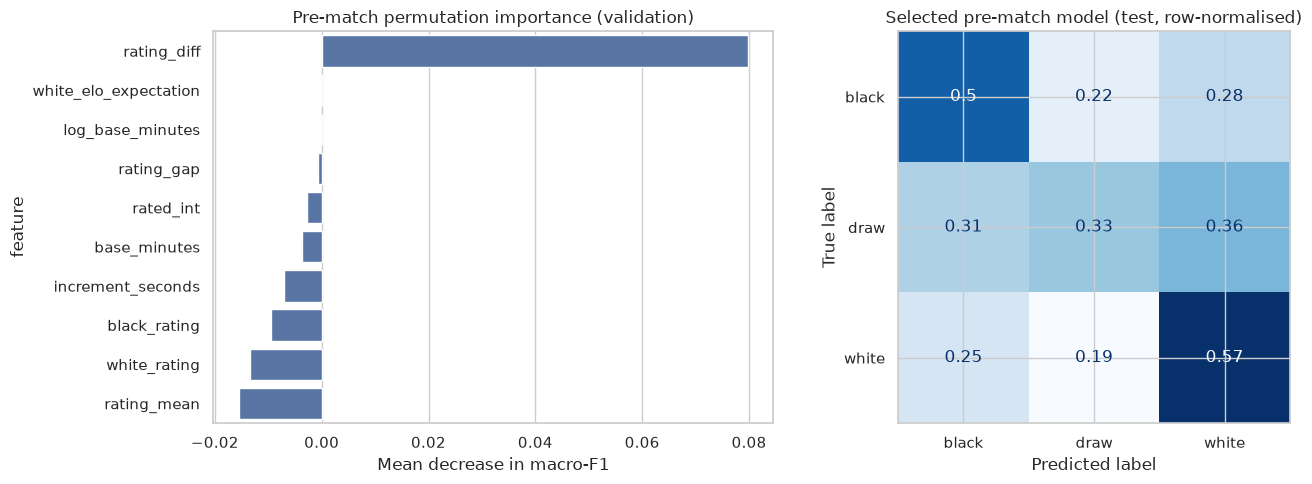

              precision    recall  f1-score   support

       black      0.619     0.496     0.551      1302
        draw      0.074     0.331     0.121       133
       white      0.659     0.566     0.609      1432

    accuracy                          0.523      2867
   macro avg      0.451     0.464     0.427      2867
weighted avg      0.614     0.523     0.560      2867



In [9]:
importance = permutation_importance(
    best_prematch,
    X_val_pre,
    y_val,
    scoring="f1_macro",
    n_repeats=8,
    random_state=SEED,
    n_jobs=-1,
)
importance_frame = pd.DataFrame({
    "feature": PREMATCH_FEATURES,
    "mean_macro_f1_drop": importance.importances_mean,
    "std": importance.importances_std,
}).sort_values("mean_macro_f1_drop", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=importance_frame, x="mean_macro_f1_drop", y="feature", color="#4c72b0", ax=axes[0])
axes[0].set_title("Pre-match permutation importance (validation)")
axes[0].set_xlabel("Mean decrease in macro-F1")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    prematch_test_proba.argmax(axis=1),
    display_labels=CLASS_NAMES,
    normalize="true",
    cmap="Blues",
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title("Selected pre-match model (test, row-normalised)")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "03_prematch_importance_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

print(classification_report(y_test, prematch_test_proba.argmax(axis=1), target_names=CLASS_NAMES, digits=3, zero_division=0))

## 5. Do human-context features improve position-based prediction?

Training and validation positions are sampled at fixed ply counts (ply 4, then every 8 plies through 160). Test positions alone are located by retrospective percentage checkpoints.

Three predictors form a controlled comparison:

1. **Direct Stockfish WDL:** uses the engine's White-win, draw, and implied Black-win probabilities without fitting a classifier.
2. **Learned position-only model:** uses the four Stockfish indicators plus `ply`, `material_total`, and `material_diff`, but no information about the players or time control.
3. **Human-context joint model (main):** uses exactly the same position features and learner, then adds the pre-match features. Any improvement over the position-only model therefore measures the value of human context under a controlled model specification.

Stockfish scores and material difference are always from White's perspective. Search-control statistics and other engine internals are neither recorded nor used.

In [10]:
TRAINING_PLIES = (4, *range(8, 161, 8))
EVALUATION_FRACTIONS = (0.10, 0.25, 0.50, 0.75, 1.00)
PIECE_VALUES = {
    chess.PAWN: 1,
    chess.KNIGHT: 3,
    chess.BISHOP: 3,
    chess.ROOK: 5,
    chess.QUEEN: 9,
}


def board_features(board: chess.Board, ply: int) -> dict[str, float]:
    """Return the three intentionally minimal manual position features."""
    white_material = sum(
        value * len(board.pieces(piece_type, chess.WHITE))
        for piece_type, value in PIECE_VALUES.items()
    )
    black_material = sum(
        value * len(board.pieces(piece_type, chess.BLACK))
        for piece_type, value in PIECE_VALUES.items()
    )
    return {
        "ply": ply,
        "material_total": white_material + black_material,
        "material_diff": white_material - black_material,
    }

In [11]:
def extract_snapshots(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Replay games and extract fixed-ply modelling or percentage evaluation snapshots."""
    records, failures = [], []
    for game_index, row in frame.iterrows():
        record_start = len(records)
        tokens = row["moves"].split()
        if row["split"] == "test":
            targets = {
                max(1, min(len(tokens), int(round(len(tokens) * fraction)))): ("percentage_evaluation", fraction)
                for fraction in EVALUATION_FRACTIONS
            }
        else:
            targets = {
                ply: ("fixed_ply_modelling", -1.0)
                for ply in TRAINING_PLIES
                if ply <= len(tokens)
            }

        board = chess.Board()
        try:
            for ply, san in enumerate(tokens, start=1):
                board.push_san(san)
                if ply in targets:
                    sampling_scheme, checkpoint = targets[ply]
                    record = {
                        "game_index": game_index,
                        "game_id": row["id"],
                        "split": row["split"],
                        "target": row["target"],
                        "sampling_scheme": sampling_scheme,
                        "checkpoint": checkpoint,
                        "fen": board.fen(),
                    }
                    record.update(board_features(board, ply))
                    records.append(record)
        except ValueError as error:
            failures.append({"game_index": game_index, "game_id": row["id"], "reason": str(error)})
            del records[record_start:]

    return pd.DataFrame.from_records(records), pd.DataFrame(failures)


snapshots, parse_failures = extract_snapshots(games)
assert not snapshots.isna().any().any()
print(f"Snapshots: {len(snapshots):,}")
print(f"Games with SAN parsing failures: {len(parse_failures)}")
display(snapshots.groupby(["split", "sampling_scheme"]).size().to_frame("snapshots"))
display(snapshots.loc[snapshots["split"].eq("test")].groupby("checkpoint").size().rename("test_games").to_frame())

Snapshots: 146,111
Games with SAN parsing failures: 0


,,snapshots
split,sampling_scheme,
test,percentage_evaluation,14179
train,fixed_ply_modelling,108534
validation,fixed_ply_modelling,23398


,test_games
checkpoint,
0.10,2803
0.25,2830
0.50,2849
0.75,2830
1.00,2867


### 5.1 Stockfish analysis and controlled model specifications

Stockfish 19 analyses each unique snapshot with a fixed 1,000-node budget, one engine thread, and `UCI_ShowWDL=True`. Only `score_cp`, `score_mate`, `wdl_wins`, and `wdl_draws` enter the experiment. The implied Black-win count is `1,000 - wins - draws`. The cache key includes the position, game/ply identity, engine binary hash, and node budget; cache writes are deduplicated and atomic.

In [12]:
STOCKFISH_NODES = 1_000
STOCKFISH_WORKERS = min(8, max(1, (os.cpu_count() or 2) // 2))
STOCKFISH_CACHE = DATA_DIR / "stockfish_features.csv"
STOCKFISH_FEATURES = ["score_cp", "score_mate", "wdl_wins", "wdl_draws"]
MANUAL_FEATURES = ["ply", "material_total", "material_diff"]
engine_config_id = f"sf19-{stockfish_hash[:12]}-nodes{STOCKFISH_NODES}"

snapshots["stockfish_key"] = [
    hashlib.sha256(f"{game_id}|{ply}|{fen}|{engine_config_id}".encode()).hexdigest()
    for game_id, ply, fen in zip(snapshots["game_id"], snapshots["ply"], snapshots["fen"])
]


def analyse_stockfish_chunk(records: list[dict]) -> list[dict]:
    """Analyse one chunk with a dedicated engine process."""
    engine = chess.engine.SimpleEngine.popen_uci(str(stockfish_path))
    engine.configure({"Threads": 1, "Hash": 16, "UCI_ShowWDL": True})
    output = []
    try:
        for record in records:
            board = chess.Board(record["fen"])
            info = engine.analyse(
                board,
                chess.engine.Limit(nodes=STOCKFISH_NODES),
                info=chess.engine.INFO_SCORE,
            )
            score = info["score"].pov(chess.WHITE)
            if "wdl" in info:
                wdl = info["wdl"].pov(chess.WHITE)
                wdl_wins, wdl_draws = wdl.wins, wdl.draws
            else:
                outcome = board.outcome(claim_draw=True)
                if outcome is None:
                    raise RuntimeError("Stockfish omitted WDL for a non-terminal position.")
                wdl_wins = 1000 if outcome.winner == chess.WHITE else 0
                wdl_draws = 1000 if outcome.winner is None else 0
            output.append({
                "stockfish_key": record["stockfish_key"],
                "score_cp": score.score(),
                "score_mate": score.mate(),
                "wdl_wins": wdl_wins,
                "wdl_draws": wdl_draws,
                "engine_config": engine_config_id,
            })
    finally:
        engine.quit()
    return output


cache_columns = ["stockfish_key", *STOCKFISH_FEATURES, "engine_config"]
if STOCKFISH_CACHE.exists():
    stockfish_cache = pd.read_csv(STOCKFISH_CACHE)
    stockfish_cache = stockfish_cache.loc[stockfish_cache["engine_config"].eq(engine_config_id), cache_columns]
    stockfish_cache = stockfish_cache.drop_duplicates("stockfish_key", keep="last")
else:
    stockfish_cache = pd.DataFrame(columns=cache_columns)

known_keys = set(stockfish_cache["stockfish_key"])
pending = snapshots.loc[~snapshots["stockfish_key"].isin(known_keys), ["stockfish_key", "fen"]]
print(f"Cached positions: {len(stockfish_cache):,}; pending positions: {len(pending):,}")

if len(pending):
    chunks = [
        pending.iloc[row_indices].to_dict("records")
        for row_indices in np.array_split(np.arange(len(pending)), STOCKFISH_WORKERS)
        if len(row_indices)
    ]
    new_records = []
    with ThreadPoolExecutor(max_workers=len(chunks)) as executor:
        futures = [executor.submit(analyse_stockfish_chunk, chunk) for chunk in chunks]
        for future in as_completed(futures):
            new_records.extend(future.result())
            print(f"Analysed {len(new_records):,}/{len(pending):,} pending positions")
    stockfish_cache = pd.concat([stockfish_cache, pd.DataFrame(new_records)], ignore_index=True)
    stockfish_cache = stockfish_cache.drop_duplicates("stockfish_key", keep="last")
    temporary = STOCKFISH_CACHE.with_suffix(".csv.tmp")
    stockfish_cache.to_csv(temporary, index=False)
    temporary.replace(STOCKFISH_CACHE)

feature_maps = stockfish_cache.set_index("stockfish_key")[STOCKFISH_FEATURES]
for feature in STOCKFISH_FEATURES:
    snapshots[feature] = snapshots["stockfish_key"].map(feature_maps[feature])

assert snapshots[["wdl_wins", "wdl_draws"]].notna().all().all()
assert snapshots[["score_cp", "score_mate"]].notna().any(axis=1).all()

for feature in PREMATCH_FEATURES:
    snapshots[feature] = snapshots["game_index"].map(games[feature])

snapshot_masks = {name: snapshots["split"].eq(name).to_numpy() for name in ("train", "validation", "test")}
y_snapshot = snapshots["target"].to_numpy()
train_game_counts = snapshots.loc[snapshot_masks["train"]].groupby("game_index").size()
train_game_targets = games.loc[train_idx, "target"].to_numpy()
class_counts = np.bincount(train_game_targets, minlength=3)
class_weights = len(train_game_targets) / (3 * class_counts)
snapshot_weights = np.ones(len(snapshots), dtype=np.float32)
train_rows = snapshots.loc[snapshot_masks["train"]]
snapshot_weights[snapshot_masks["train"]] = [
    class_weights[target] / train_game_counts.loc[game_index]
    for target, game_index in zip(train_rows["target"], train_rows["game_index"])
]
snapshot_weights[snapshot_masks["train"]] /= snapshot_weights[snapshot_masks["train"]].mean()

MODEL_SPECS = {
    "Learned position only": STOCKFISH_FEATURES + MANUAL_FEATURES,
    "Human-context joint model": PREMATCH_FEATURES + STOCKFISH_FEATURES + MANUAL_FEATURES,
}


def stockfish_wdl_proba(frame: pd.DataFrame) -> np.ndarray:
    """Convert Stockfish WDL counts to Black-win, draw, and White-win probabilities."""
    white_wins = frame["wdl_wins"].to_numpy(dtype=float)
    draws = frame["wdl_draws"].to_numpy(dtype=float)
    black_wins = np.clip(1_000.0 - white_wins - draws, 0.0, 1_000.0)
    probabilities = np.column_stack([black_wins, draws, white_wins])
    return probabilities / probabilities.sum(axis=1, keepdims=True)


position_models = {}
validation_probas = {
    "Direct Stockfish WDL": stockfish_wdl_proba(snapshots.loc[snapshot_masks["validation"]]),
}
test_probas = {
    "Direct Stockfish WDL": stockfish_wdl_proba(snapshots.loc[snapshot_masks["test"]]),
}

for name, features in MODEL_SPECS.items():
    model = HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=240,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=SEED,
    )
    model.fit(
        snapshots.loc[snapshot_masks["train"], features],
        y_snapshot[snapshot_masks["train"]],
        sample_weight=snapshot_weights[snapshot_masks["train"]],
    )
    position_models[name] = model
    validation_probas[name] = model.predict_proba(snapshots.loc[snapshot_masks["validation"], features])
    test_probas[name] = model.predict_proba(snapshots.loc[snapshot_masks["test"], features])

validation_comparison = pd.DataFrame([
    metric_row(name, y_snapshot[snapshot_masks["validation"]], probabilities)
    for name, probabilities in validation_probas.items()
]).sort_values("macro_f1", ascending=False)
display(validation_comparison.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

MAIN_MODEL_NAME = "Human-context joint model"
main_model = position_models[MAIN_MODEL_NAME]
main_features = MODEL_SPECS[MAIN_MODEL_NAME]
print(f"Main model: {MAIN_MODEL_NAME}")

Cached positions: 146,111; pending positions: 0


,model,accuracy,macro_f1,log_loss
2,Human-context joint model,0.651,0.524,0.788
1,Learned position only,0.586,0.499,0.934
0,Direct Stockfish WDL,0.478,0.437,6.723


Main model: Human-context joint model


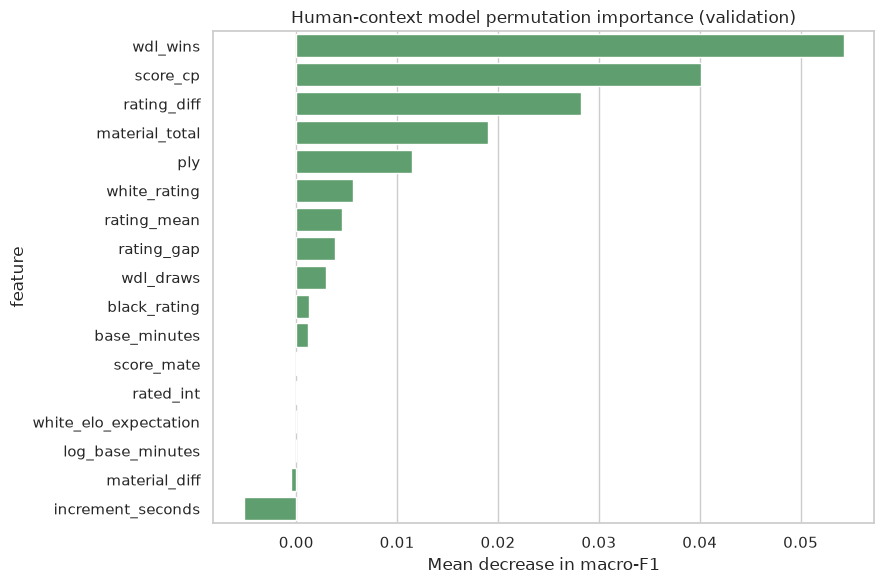

In [13]:
main_importance = permutation_importance(
    main_model,
    snapshots.loc[snapshot_masks["validation"], main_features],
    y_snapshot[snapshot_masks["validation"]],
    scoring="f1_macro",
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1,
)
importance_frame = pd.DataFrame({
    "feature": main_features,
    "mean_macro_f1_drop": main_importance.importances_mean,
    "std": main_importance.importances_std,
}).sort_values("mean_macro_f1_drop", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_frame, x="mean_macro_f1_drop", y="feature", color="#55a868")
plt.title("Human-context model permutation importance (validation)")
plt.xlabel("Mean decrease in macro-F1")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_human_context_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Controlled comparison and progressive evaluation

The comparison separates three questions: what the strategy engine predicts directly, what a classifier can learn from the position alone, and what changes when human context is added. The two learned models share the same algorithm and training procedure. The complete human-context model is the prespecified main model and is used for the final diagnostic analysis.

,model,accuracy,macro_f1,log_loss
2,Human-context joint model,0.687,0.545,0.714
1,Learned position only,0.634,0.520,0.853
0,Direct Stockfish WDL,0.476,0.434,5.751


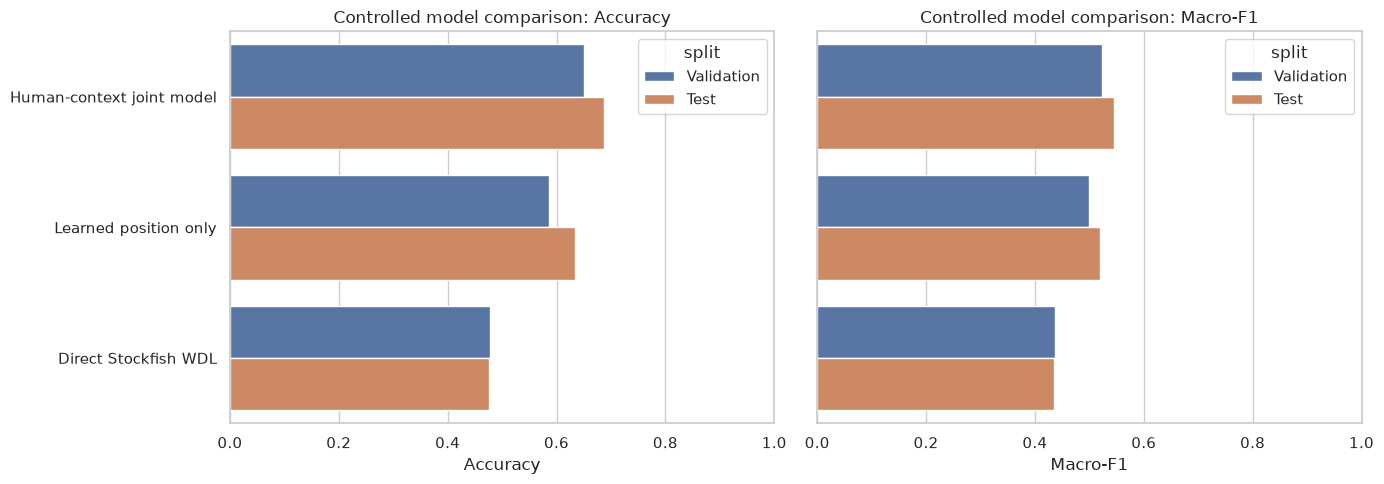

,comparison,accuracy_gain,macro_f1_gain,log_loss_reduction
0,Human context minus position-only,+0.054,+0.025,+0.139


In [14]:
test_comparison = pd.DataFrame([
    metric_row(name, y_snapshot[snapshot_masks["test"]], probabilities)
    for name, probabilities in test_probas.items()
]).sort_values("macro_f1", ascending=False)
display(test_comparison.style.format({
    "accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}",
}))

comparison_long = pd.concat([
    validation_comparison.assign(split="Validation"),
    test_comparison.assign(split="Test"),
], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for axis, metric, title in zip(axes, ["accuracy", "macro_f1"], ["Accuracy", "Macro-F1"]):
    sns.barplot(data=comparison_long, x=metric, y="model", hue="split", ax=axis)
    axis.set_xlim(0, 1)
    axis.set_title(f"Controlled model comparison: {title}")
    axis.set_xlabel(title)
    axis.set_ylabel("")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "05_controlled_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

context_test = test_comparison.set_index("model")
context_gain = pd.DataFrame({
    "comparison": ["Human context minus position-only"],
    "accuracy_gain": [context_test.loc[MAIN_MODEL_NAME, "accuracy"] - context_test.loc["Learned position only", "accuracy"]],
    "macro_f1_gain": [context_test.loc[MAIN_MODEL_NAME, "macro_f1"] - context_test.loc["Learned position only", "macro_f1"]],
    "log_loss_reduction": [context_test.loc["Learned position only", "log_loss"] - context_test.loc[MAIN_MODEL_NAME, "log_loss"]],
})
display(context_gain.style.format({
    "accuracy_gain": "{:+.3f}", "macro_f1_gain": "{:+.3f}", "log_loss_reduction": "{:+.3f}",
}))

,model,progress_pct,accuracy,macro_f1,n
1,Direct Stockfish WDL,10,0.103,0.106,2803
2,Direct Stockfish WDL,25,0.242,0.243,2830
3,Direct Stockfish WDL,50,0.474,0.416,2849
4,Direct Stockfish WDL,75,0.649,0.542,2830
5,Direct Stockfish WDL,100,0.901,0.779,2867
0,Human-context joint model,0,0.523,0.427,2867
11,Human-context joint model,10,0.584,0.435,2803
12,Human-context joint model,25,0.588,0.450,2830
13,Human-context joint model,50,0.649,0.498,2849
14,Human-context joint model,75,0.714,0.570,2830


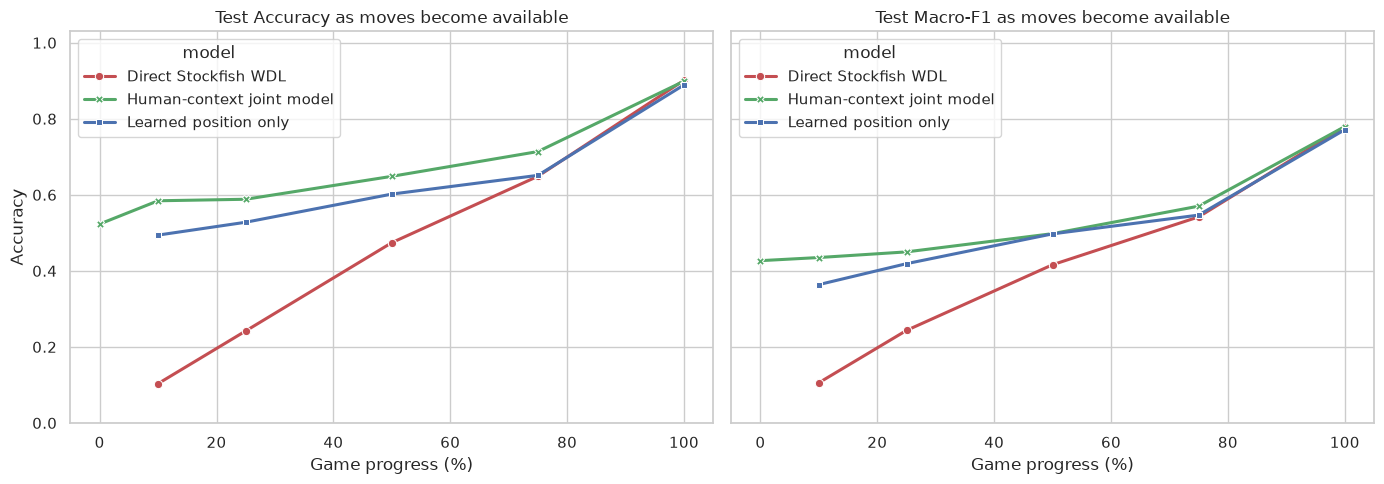

,model,accuracy_aupc_10_to_100,macro_f1_aupc_10_to_100
2,Human-context joint model,0.683,0.541
1,Learned position only,0.630,0.521
0,Direct Stockfish WDL,0.500,0.437


In [15]:
test_snapshots = snapshots.loc[snapshot_masks["test"]].reset_index(drop=True)
curve_rows = []

# Only the main forecasting system has a meaningful 0% estimate, supplied by the pre-match model.
curve_rows.append({
    "model": MAIN_MODEL_NAME,
    "progress_pct": 0,
    "accuracy": accuracy_score(y_test, prematch_test_proba.argmax(axis=1)),
    "macro_f1": f1_score(y_test, prematch_test_proba.argmax(axis=1), average="macro", zero_division=0),
    "n": len(y_test),
})

for model_name, probabilities in test_probas.items():
    for checkpoint in EVALUATION_FRACTIONS:
        mask = test_snapshots["checkpoint"].eq(checkpoint).to_numpy()
        targets = test_snapshots.loc[mask, "target"].to_numpy()
        predictions = probabilities[mask].argmax(axis=1)
        curve_rows.append({
            "model": model_name,
            "progress_pct": int(checkpoint * 100),
            "accuracy": accuracy_score(targets, predictions),
            "macro_f1": f1_score(targets, predictions, average="macro", zero_division=0),
            "n": len(targets),
        })

model_curves = pd.DataFrame(curve_rows).sort_values(["model", "progress_pct"])
display(model_curves.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
palette = {
    "Direct Stockfish WDL": "#c44e52",
    "Learned position only": "#4c72b0",
    MAIN_MODEL_NAME: "#55a868",
}
for axis, metric, title in zip(axes, ["accuracy", "macro_f1"], ["Accuracy", "Macro-F1"]):
    sns.lineplot(
        data=model_curves, x="progress_pct", y=metric, hue="model",
        style="model", markers=True, dashes=False, linewidth=2.2,
        palette=palette, ax=axis,
    )
    axis.set_ylim(0, 1.03)
    axis.set_xlabel("Game progress (%)")
    axis.set_ylabel(title)
    axis.set_title(f"Test {title} as moves become available")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "06_progressive_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# For a fair comparison, all three AUPC values use the common 10–100% interval.
aupc_rows = []
for model_name in test_probas:
    frame = model_curves.loc[
        model_curves["model"].eq(model_name) & model_curves["progress_pct"].ge(10)
    ].sort_values("progress_pct")
    progress_axis = frame["progress_pct"].to_numpy() / 100
    aupc_rows.append({
        "model": model_name,
        "accuracy_aupc_10_to_100": np.trapezoid(frame["accuracy"], x=progress_axis) / 0.9,
        "macro_f1_aupc_10_to_100": np.trapezoid(frame["macro_f1"], x=progress_axis) / 0.9,
    })
display(pd.DataFrame(aupc_rows).sort_values("macro_f1_aupc_10_to_100", ascending=False).style.format({
    "accuracy_aupc_10_to_100": "{:.3f}", "macro_f1_aupc_10_to_100": "{:.3f}",
}))

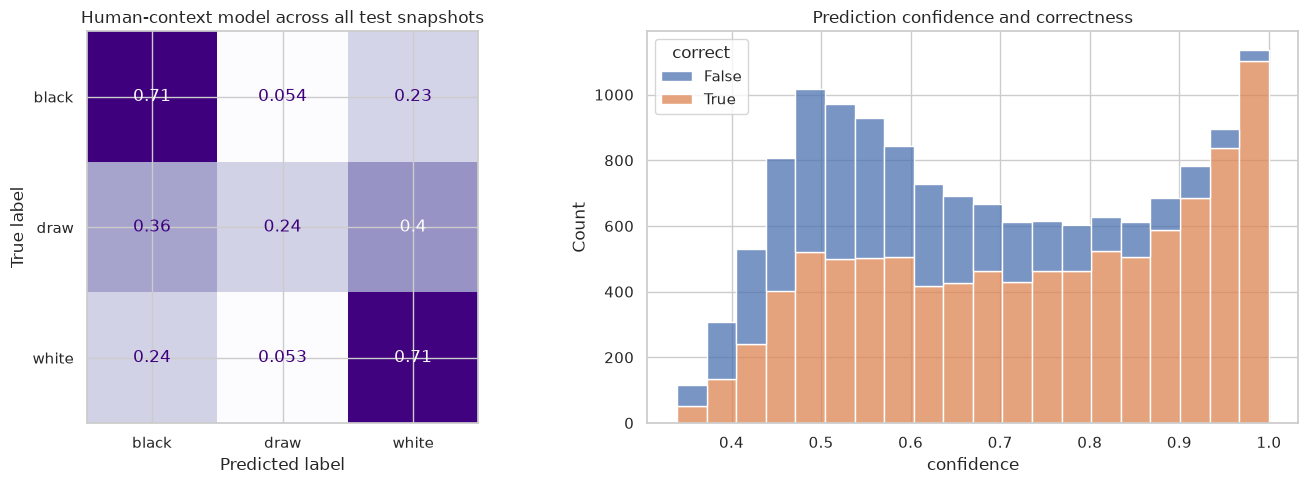

              precision    recall  f1-score   support

       black      0.704     0.712     0.708      6447
        draw      0.180     0.240     0.206       663
       white      0.738     0.707     0.722      7069

    accuracy                          0.687     14179
   macro avg      0.541     0.553     0.545     14179
weighted avg      0.696     0.687     0.692     14179



In [16]:
main_test_proba = test_probas[MAIN_MODEL_NAME]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(
    test_snapshots["target"],
    main_test_proba.argmax(axis=1),
    display_labels=CLASS_NAMES,
    normalize="true",
    cmap="Purples",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Human-context model across all test snapshots")

confidence = main_test_proba.max(axis=1)
correct = main_test_proba.argmax(axis=1) == test_snapshots["target"].to_numpy()
confidence_frame = pd.DataFrame({"confidence": confidence, "correct": correct})
sns.histplot(data=confidence_frame, x="confidence", hue="correct", bins=20, multiple="stack", ax=axes[1])
axes[1].set_title("Prediction confidence and correctness")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "07_main_model_confusion_confidence.png", dpi=300, bbox_inches="tight")
plt.show()

print(classification_report(
    test_snapshots["target"],
    main_test_proba.argmax(axis=1),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

## 7. Conclusions, limitations, and responsible interpretation

The experiment supports a focused interpretation:

1. **Engine evaluation is strong but not sufficient:** direct Stockfish WDL provides a principled objective estimate, yet it is calibrated for engine play rather than this population of human games.
2. **Learning the human outcome mapping matters:** the position-only classifier can adapt the same engine and manual signals to observed human results.
3. **Human context adds information:** the controlled comparison with the same learner shows whether ratings, rated status, and time control improve prediction beyond the current position.
4. **Evidence strengthens through the game:** all position-based predictors improve as more moves reveal the state of play. The endpoint remains a genuine prediction; the known result is never substituted.

### Limitations

- Stockfish uses a deliberately small 1,000-node budget; deeper analysis could improve feature quality at much greater computational cost.
- Stockfish WDL is based on engine self-play, not rating- and time-specific human behaviour.
- The dataset has no per-move clock, so time pressure cannot be modelled directly.
- Random game-level splitting does not test temporal drift or completely unseen player populations.
- Percentage checkpoints use final length only to locate retrospective test positions; deployed inference uses current ply.

### Generative AI use declaration

OpenAI Codex was used to assist with structuring the analysis, drafting Python code, debugging, and language editing for the notebook, report, and README. The project authors reviewed and validated all generated content, methodological decisions, code execution, numerical results, references, and interpretations, and retain full responsibility for the submitted work. No generative-AI-produced observations, outcomes, or labels were added to the dataset.